In [1]:
import pandas as pd

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [ ]:
df = pd.read_csv("state_data.csv")
print(df.shape)
print(df.head())
print(df.tail())
print(df.iloc[39])
#different columns are collecting different data 
#first state is Alaska, last is Wyoming, and there's 52 entries total. It indexes starting at zero and Puerto Rico is also included, so there's 52.

(52, 4)
  state   latitude   longitude        name
0    AK  63.588753 -154.493062      Alaska
1    AL  32.318231  -86.902298     Alabama
2    AR  35.201050  -91.831833    Arkansas
3    AZ  34.048928 -111.093731     Arizona
4    CA  36.778261 -119.417932  California
   state   latitude   longitude           name
47    VT  44.558803  -72.577841        Vermont
48    WA  47.751074 -120.740139     Washington
49    WI  43.784440  -88.787868      Wisconsin
50    WV  38.597626  -80.454903  West Virginia
51    WY  43.075968 -107.290284        Wyoming
state                 PR
latitude       18.220833
longitude     -66.590149
name         Puerto Rico
Name: 39, dtype: object


In [22]:
median_lat = (df["latitude"].median())
median_long = (df["longitude"].median())
print(median_lat, median_long)

39.4355155 -89.093198


In [28]:
df["dist_latitude"] =(df["latitude"]-median_lat).abs()
df["dist_longitude"] =(df["longitude"]-median_long).abs()
print(df.shape)

(52, 6)


In [34]:
closest_lat = df["dist_latitude"].min()
print(f"{closest_lat:.2f}")
farthest_lat = df["dist_latitude"].max()
print(f"{farthest_lat:.2f}")
closest_long = df["dist_longitude"].min()
print(f"{closest_long:.2f}")
farthest_long = df["dist_longitude"].max()
print(f"{farthest_long:.2f}")


0.11
24.15
0.31
66.57


In [ ]:
print(df.nlargest(3, "dist_latitude"))
#pulls the top n largest in that column. Could be useful so you don't have to find largest, second largest, etc independently 

   state   latitude   longitude         name  dist_latitude  dist_longitude
0     AK  63.588753 -154.493062       Alaska      24.153237       65.399864
39    PR  18.220833  -66.590149  Puerto Rico      21.214683       22.503049
11    HI  19.898682 -155.665857       Hawaii      19.536834       66.572659


In [ ]:
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.
/opt/anaconda3/lib/python3.13/site-packages/seaborn/_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import gaussian_kde


In [60]:
import matplotlib.pyplot as plt

In [54]:
df = sns.load_dataset("planets")
print(df.shape)


(1035, 6)


In [ ]:
df = df.dropna(axis=1)
print(df.shape)
print(df.head)
print(df.tail)
#1035 rows, 3 columns
#first coloumn is just the index of the data, method is the method of detecting the planet, number is the number of planets detetcted(?), and year is year it was detected 

(1035, 3)
<bound method NDFrame.head of                method  number  year
0     Radial Velocity       1  2006
1     Radial Velocity       1  2008
2     Radial Velocity       1  2011
3     Radial Velocity       1  2007
4     Radial Velocity       1  2009
...               ...     ...   ...
1030          Transit       1  2006
1031          Transit       1  2007
1032          Transit       1  2007
1033          Transit       1  2008
1034          Transit       1  2008

[1035 rows x 3 columns]>
<bound method NDFrame.tail of                method  number  year
0     Radial Velocity       1  2006
1     Radial Velocity       1  2008
2     Radial Velocity       1  2011
3     Radial Velocity       1  2007
4     Radial Velocity       1  2009
...               ...     ...   ...
1030          Transit       1  2006
1031          Transit       1  2007
1032          Transit       1  2007
1033          Transit       1  2008
1034          Transit       1  2008

[1035 rows x 3 columns]>


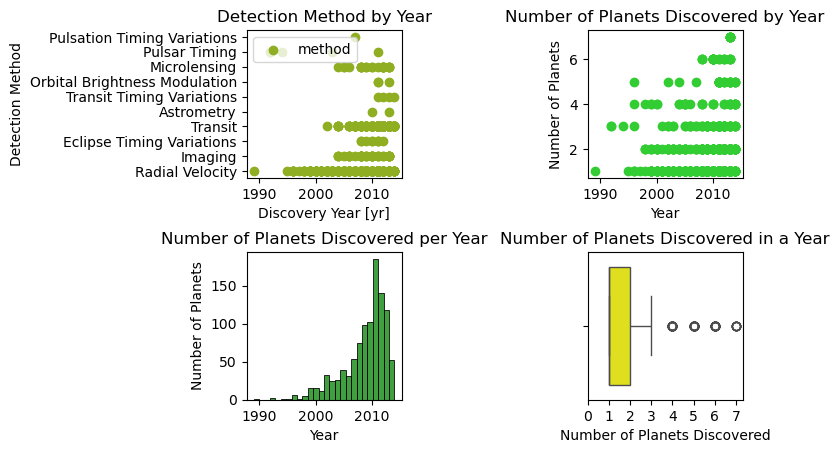

In [125]:
fig, axs = plt.subplots(2, 2)

axs[0, 0].scatter('year', 'method', data=df, color='xkcd:icky green')
axs[0, 0].set_title('Detection Method by Year')
axs[0, 0].set_xlabel('Discovery Year [yr]')
axs[0, 0].set_ylabel('Detection Method')
axs[0, 0].legend(loc='upper left')

axs[0,1].scatter('year','number', data=df, color='limegreen')
axs[0,1].set_title('Number of Planets Discovered by Year')
#There aren't really any units I can add 
axs[0,1].set_xlabel('Year')
axs[0,1].set_ylabel('Number of Planets')


sns.histplot(data=df, x="year", ax=axs[1, 0], color = 'green')
axs[1,0].set_title('Number of Planets Discovered per Year')
axs[1,0].set_xlabel('Year')
axs[1,0].set_ylabel('Number of Planets')
sns.boxplot(data=df, x="number", ax=axs[1,1], color = 'yellow')
axs[1,1].set_title('Number of Planets Discovered in a Year')
axs[1,1].set_xlabel('Number of Planets Discovered')
axs[1,1].set_xticks(range(0,8,1))
#I found this online to manually adjust the spacing since they were too close together 
plt.subplots_adjust(
    hspace=0.5,
    wspace=1.2
)
plt.show()

#Subplot 1 is detection method by year, subplot 2 is number of planets observed in each bin from 1 planet to 8 by year (basically unreadable unfortunately), and I did both by year because there were only three data columns
#Then the histogram in subplot 3 is number of planets discovered by year again, since it was discrete numbers and I thought it would be a meaningful graph
#And the final boxplot is number of planets discovered, because I didn't really have any continuous data to work with 
#I learned that this was probably not a great dataset to pick for this activity
#But it was interesting to see the changes in detection method over the years and how even after introducing new methods we still use radial velocity so much
#